# SPOT: demo of the new features (Oct 2026)

A self-contained tour of what is new in SPOT, on a small synthetic time-lapse (no download needed) of 60 cells of
three phenotypes that differ in **shape**, **appearance** (texture) and **motion**:

| phenotype | shape | texture | motion |
|---|---|---|---|
| `round` | circle | fine grain | slow random drift |
| `elongated` | ellipse | coarse stripes | fast back-and-forth along its axis |
| `lobed` | 5-lobed star | blobs | rotates |

Every cell has a random size, orientation and illumination gain, and the cells on the right half of the frame are
brighter (a "plate" batch effect), so the confound and rotation helpers have something to remove.

Sections:
1. SAM phenome extraction with the new defaults (masked appearance / motion, fast parallel implementation) and the GPU variants
2. Masked vs unmasked appearance: the appearance features no longer encode shape
3. Normalisation and equal weighting of the SAM sets and feature families (`weight_sam_features`)
4. Regressing out confounders: the batch by default, nuisances such as illumination per dataset (`regress_out_confounders`)
5. Rotation-invariant features (`compute_rotation_averaged_features`)
6. Multi-scale SAM module selection (`hierarchical_cluster_features_into_SAM_modules`)
7. UMAP and PaCMAP embeddings
8. Pretrained detection / segmentation networks from Zenodo, in PyTorch

The same code is in `examples/SPOT_demo_new_features.py` (script) and `examples/SPOT_demo_new_features.ipynb` (notebook).
Figures are also saved to `examples/output_new_features/`.

In [1]:
import os
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.ndimage as ndimage
from skimage.draw import polygon

import SPOT.Analysis.preprocessing as preprocess
import SPOT.Analysis.sam_analysis as SAM
import SPOT.Features.augment as augment
import SPOT.Features.features as SPOT_features
from SPOT.Tracking.optical_flow import extract_vid_optflow, get_farneback_flow_params

warnings.simplefilter('ignore')
N_JOBS = max(1, (os.cpu_count() or 2) // 2)  # parallel CPU extraction (the *_fast implementation)
DOWNLOAD_WEIGHTS = False  # section 8 downloads ~250 MB of pretrained weights from Zenodo if True
OUTDIR = os.path.join(os.path.dirname(os.path.abspath(__file__)) if '__file__' in globals() else os.getcwd(),
                      'output_new_features')
os.makedirs(OUTDIR, exist_ok=True)


def show(fig, name):
    """ save the figure to OUTDIR and display it """
    fig.savefig(os.path.join(OUTDIR, name), dpi=120, bbox_inches='tight')
    plt.show()

## 0. A synthetic time-lapse
The texture is attached to each cell and moves (and rotates) with it, so the optical flow computed from the video is
the cells' real motion. Contours are given as `(n_cells, n_frames, n_points, 2)` (row, col) arrays, as produced by the
SPOT tracking / segmentation stage.

video (10, 256, 960) flow (9, 256, 960, 2) contours (60, 10, 200, 2)


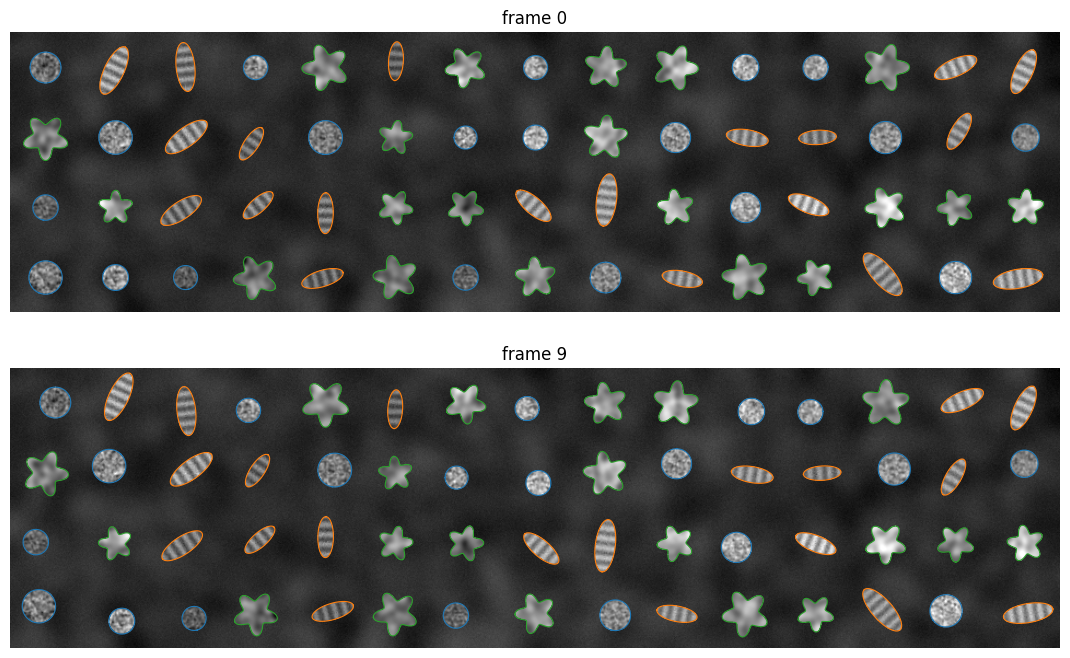

In [2]:
def make_movie(n_per_type=20, T=10, cell=64, n_pts=200, seed=0, same_texture=False):
    rng = np.random.default_rng(seed)
    types = np.repeat(['round', 'elongated', 'lobed'], n_per_type)
    rng.shuffle(types)
    n_rows, n_cols = 4, len(types) // 4
    H, W = n_rows * cell, n_cols * cell
    t = np.linspace(0, 2 * np.pi, n_pts - 1, endpoint=False)
    yy, xx = np.mgrid[-cell // 2:cell // 2, -cell // 2:cell // 2]
    textures = {'round': lambda r: ndimage.gaussian_filter(r.standard_normal((cell, cell)), 0.8),
                'elongated': lambda r: np.sin(2 * np.pi * xx / 9.) + 0.3 * r.standard_normal((cell, cell)),
                'lobed': lambda r: ndimage.gaussian_filter(r.standard_normal((cell, cell)), 3.)}
    cells = []
    for i, kind in enumerate(types):
        row, col = divmod(i, n_cols)
        tex = textures['round' if same_texture else kind](rng)  # same_texture: only the shape and motion differ
        cells.append(dict(kind=kind, center=np.array([(row + 0.5) * cell, (col + 0.5) * cell]),
                          size=rng.uniform(0.8, 1.2), angle=rng.uniform(0, 2 * np.pi), tex=tex / tex.std(),
                          gain=rng.uniform(0.75, 1.25),  # illumination: a nuisance unrelated to the phenotype
                          plate=int(col >= n_cols // 2), phase=rng.uniform(0, 2 * np.pi)))

    boundaries = np.zeros((len(cells), T, n_pts, 2))
    vid = np.zeros((T, H, W))
    masks = np.zeros((T, H, W), dtype=bool)
    bg = 60 + 8 * ndimage.gaussian_filter(rng.standard_normal((H, W)), 10) / 0.03
    for k in range(T):
        frame = bg + 3 * rng.standard_normal((H, W))
        for i, c in enumerate(cells):
            s, kind = c['size'], c['kind']
            if kind == 'round':
                r_t, ang, shift = 13 * s * np.ones_like(t), c['angle'], 1.0 * k * np.array([np.sin(c['phase']), np.cos(c['phase'])])
                ry, rx = r_t * np.sin(t), r_t * np.cos(t)
            elif kind == 'elongated':
                ang = c['angle']
                d = 7 * np.sin(c['phase'] + 0.9 * k)  # back and forth along the long axis
                shift = d * np.array([np.sin(ang), np.cos(ang)])
                ry, rx = 8 * s * np.sin(t), 21 * s * np.cos(t)
            else:
                ang = c['angle'] + 0.25 * k  # rotating
                shift = np.zeros(2)
                r_t = 15 * s * (1 + 0.28 * np.cos(5 * t))
                ry, rx = r_t * np.sin(t), r_t * np.cos(t)
            ctr = c['center'] + shift
            cnt = np.c_[ctr[0] + ry * np.cos(ang) + rx * np.sin(ang), ctr[1] - ry * np.sin(ang) + rx * np.cos(ang)]
            boundaries[i, k] = np.vstack([cnt, cnt[:1]])
            rr, cc = polygon(boundaries[i, k, :, 0], boundaries[i, k, :, 1], (H, W))
            # texture coordinates in the cell's own (rotating, moving) frame
            dy, dx = rr - ctr[0], cc - ctr[1]
            u = cell // 2 + dy * np.cos(ang) - dx * np.sin(ang)
            v = cell // 2 + dy * np.sin(ang) + dx * np.cos(ang)
            tex = ndimage.map_coordinates(c['tex'], [u, v], order=1, mode='wrap')
            frame[rr, cc] = c['gain'] * (130 + 28 * tex) + 30 * c['plate']  # plate 1 is brighter: a batch effect
            masks[k, rr, cc] = True
        vid[k] = frame
    vid = np.clip(vid, 0, 255).astype(np.uint8)
    meta = pd.DataFrame([dict(cell=i, kind=c['kind'], size=c['size'], gain=c['gain'], plate=c['plate'])
                         for i, c in enumerate(cells)])
    return vid, masks, boundaries, meta


vid, masks, boundaries, cell_meta = make_movie()
T = len(vid)
flow = extract_vid_optflow(vid, get_farneback_flow_params(), rescale_intensity=True)  # (T-1, H, W, 2)
print('video', vid.shape, 'flow', flow.shape, 'contours', boundaries.shape)

fig, axes = plt.subplots(2, 1, figsize=(14, 8))
for ax, k in zip(axes, (0, T - 1)):
    ax.imshow(vid[k], cmap='gray')
    for i in range(len(boundaries)):
        ax.plot(boundaries[i, k, :, 1], boundaries[i, k, :, 0], lw=0.8,
                color={'round': 'tab:blue', 'elongated': 'tab:orange', 'lobed': 'tab:green'}[cell_meta.kind[i]])
    ax.set_title('frame %d' % k); ax.axis('off')
show(fig, '0_movie.png')

## 1. SAM phenome extraction: new defaults
The three feature functions now default to
- `use_mask=True`: the appearance (Haralick, SIFT) and motion SIFT features only use the pixels **inside** the cell, so
  they do not double count the outline (pass the segmentation `masks` to intersect with the foreground);
- `fast=True` with `n_jobs`: an optimised implementation (per-cell crops, vectorised ECT / shape context, parallel over
  cells and frames) that gives the same features as the original code.

`use_mask=False` and `fast=False` give the original SAM features and implementation.

In [3]:
t0 = time.time()
shape_feats, shape_names, _ = SPOT_features.compute_boundary_morphology_features(boundaries, vid.shape[1:], n_jobs=N_JOBS)
t_shape = time.time() - t0
t0 = time.time()
app_feats, app_names, _ = SPOT_features.compute_boundary_texture_features(vid, boundaries, masks=masks, n_jobs=N_JOBS)
t_app = time.time() - t0
t0 = time.time()
mot_feats, mot_names, _ = SPOT_features.compute_boundary_motion_features(flow, boundaries, masks=masks, n_jobs=N_JOBS)
t_mot = time.time() - t0
print('shape %s in %.1fs, appearance %s in %.1fs, motion %s in %.1fs' % (shape_feats.shape, t_shape, app_feats.shape,
                                                                       t_app, mot_feats.shape, t_mot))

shape (60, 10, 1651) in 8.4s, appearance (60, 10, 149) in 1.7s, motion (60, 9, 360) in 3.7s


The original implementation (`fast=False`) gives the same features, more slowly:

In [4]:
t0 = time.time()
app_orig, app_orig_names, _ = SPOT_features.compute_boundary_texture_features(vid, boundaries, masks=masks, fast=False)
t_orig = time.time() - t0
same = np.allclose(app_orig, app_feats, rtol=1e-6, atol=1e-8, equal_nan=True)
print('appearance: original %.1fs vs fast %.1fs (n_jobs=%d); identical features: %s' % (t_orig, t_app, N_JOBS, same))

appearance: original 47.7s vs fast 1.7s (n_jobs=16); identical features: True


On a GPU, the `*_torch` variants batch the polygon rasterisation, Haralick, SIFT, ECT and curl / divergence
(PyTorch is installed with SPOT; install a CUDA build of torch for the GPU).

In [5]:
import torch  # noqa: E402

if torch.cuda.is_available():
    from SPOT.Features import features_torch
    t0 = time.time()
    shape_gpu, _, _ = features_torch.compute_boundary_morphology_features_torch(boundaries, vid.shape[1:], device='cuda')
    print('shape features on the GPU in %.1fs; max abs difference to the CPU: %.2e'
          % (time.time() - t0, np.nanmax(np.abs(shape_gpu - shape_feats))))
else:
    print('no CUDA GPU available: skipping the *_torch variants')

shape features on the GPU in 25.5s; max abs difference to the CPU: 0.00e+00


## 2. Masked vs unmasked appearance
With `use_mask=False` (the original SAM features) Haralick and SIFT are computed on the bounding box crop, so they also
describe the outline. To see this, make the same movie with **the same texture in every cell**: the phenotypes then
differ only in shape and motion, and appearance should not be able to tell them apart. Cross-validated accuracy
(grouped by cell) of classifying the phenotype from the appearance features alone (chance = 0.33):

In [6]:
from sklearn.linear_model import LogisticRegression  # noqa: E402
from sklearn.model_selection import GroupKFold, cross_val_score  # noqa: E402
from sklearn.pipeline import make_pipeline  # noqa: E402
from sklearn.preprocessing import StandardScaler  # noqa: E402

vid_same, masks_same, boundaries_same, meta_same = make_movie(same_texture=True)
kind_rows = np.repeat(meta_same['kind'].to_numpy(), T)
cell_rows = np.repeat(np.arange(len(boundaries_same)), T)


def phenotype_from_appearance(A):
    A = np.nan_to_num(A.reshape(-1, A.shape[-1]))
    A = A[:, A.std(0) > 0]
    model = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000))
    return cross_val_score(model, A, kind_rows, groups=cell_rows, cv=GroupKFold(4)).mean()


for use_mask in (False, True):
    A, _, _ = SPOT_features.compute_boundary_texture_features(vid_same, boundaries_same, use_mask=use_mask,
                                                              masks=masks_same if use_mask else None, n_jobs=N_JOBS)
    print('use_mask=%s: phenotype accuracy from appearance %.2f' % (use_mask, phenotype_from_appearance(A)))

use_mask=False: phenotype accuracy from appearance 0.88


use_mask=True: phenotype accuracy from appearance 0.46


## 3. Normalisation and equal weighting of the SAM sets and feature families
Rows are cell x frame (motion has one frame fewer). Features are normalised per feature (zero / constant features
removed, z-score + Yeo-Johnson power transform). The SAM sets have very different numbers of features (hundreds of
shape context / ECT and SIFT bins against a handful of intensity or speed features), so without weighting the largest
families dominate every distance. `weight_sam_features` gives shape, appearance and motion the same total variance
and, within each, every feature family (curvature, Fourier, shape context, Haralick, SIFT, regional speed, ...) the same
weight. `sam_feature_groups` lists the families.

In [7]:
n_cells = len(boundaries)
rows = [(i, k) for i in range(n_cells) for k in range(T - 1)]
X_raw = np.array([np.hstack([shape_feats[i, k], app_feats[i, k], mot_feats[i, k]]) for i, k in rows])
names = np.hstack([shape_names, app_names, mot_names]).astype(str)
meta = pd.DataFrame(rows, columns=['cell', 'frame']).merge(cell_meta, on='cell')
raw = pd.DataFrame(X_raw, columns=names)

X, feat_names = preprocess.remove_nan_variance_features(np.nan_to_num(X_raw), names)
X, feat_names = preprocess.remove_zero_features(X, feat_names)
X, feat_names, _, _ = preprocess.power_transform_and_scale_features(X, feat_names, np.zeros(len(X), dtype=int))
X = np.nan_to_num(X)
sets, families = preprocess.sam_feature_groups(feat_names)
print('normalised features:', X.shape)
print(pd.crosstab(sets, families).T.assign(total=lambda d: d.sum(axis=1)).query('total > 0').drop(columns='total'))

Xw = preprocess.weight_sam_features(X, feat_names, group_weighting=True, set_weighting=True)
share = pd.DataFrame({'unweighted': pd.Series(X.var(0)).groupby(sets).sum(),
                      'weighted': pd.Series(Xw.var(0)).groupby(sets).sum()})
print((share / share.sum()).round(3))

normalised features: (540, 1683)
row_0                           appearance  motion  shape
col_0                                                    
Euler characteristic transform           0       0    746
Fourier                                  0       0     99
Haralick texture                        13       0      0
SIFT                                   128       0      0
binary morphology                        0       0     43
contour geometry                         0       0     13
curl signed                              0      32      0
curvature                                0       0      7
divergence signed                        0      32      0
elliptic Fourier                         0       0     37
flow vector SIFT                         0     128      0
global intensity                         2       0      0
global motion                            0      10      0
regional intensity                       6       0      0
regional speed                         

## 4. Regressing out confounders
The default confounder is the **batch** (plate, experiment, imaging session). `regress_out_confounders` removes the
mean (and optionally scale, `batch_scale=True`) of every batch; `reference=` fits on e.g. control cells only, so
condition differences are not regressed away. Features that remain associated are dropped (`drop_associated=True`).
`confound_association` measures the association of each feature with a confounder (between-batch variance share
eta^2 for categorical, |Spearman rho| for continuous ones).

Continuous covariates such as size or intensity are set **per dataset**, only when they are nuisances there. In this
dataset the illumination of each cell (measured by its mean intensity) is one, so it is added in a second step. Cell
size, by contrast, differs between the phenotypes here: regressing it out would remove much of what separates them.

In [8]:
plate = meta['plate'].to_numpy()
CONTINUOUS_CONFOUNDS = {'intensity': raw['mean_intensity'].to_numpy()}  # per dataset; {} for none


def confound_summary(Xa, na, Xb, nb, **cov):
    before = preprocess.confound_association(Xa, na, **cov)
    after = preprocess.confound_association(Xb, nb, **cov)
    return pd.DataFrame({'median before': before.groupby('covariate').association.median(),
                         'median after': after.groupby('covariate').association.median(),
                         'max before': before.groupby('covariate').association.max(),
                         'max after': after.groupby('covariate').association.max()}).round(3)


# default: batch only
Xb, names_b, model_b = preprocess.regress_out_confounders(X, feature_names=feat_names, categorical={'plate': plate},
                                                          return_model=True)
print('batch only (%d features dropped):' % len(model_b.dropped_features_))
print(confound_summary(X, feat_names, Xb, names_b, categorical={'plate': plate}, continuous=CONTINUOUS_CONFOUNDS))

# this dataset: batch + illumination
Xc, names_c, model = preprocess.regress_out_confounders(X, feature_names=feat_names, categorical={'plate': plate},
                                                        continuous=CONTINUOUS_CONFOUNDS, return_model=True)
print('batch + %s (%d features dropped):' % (', '.join(CONTINUOUS_CONFOUNDS), len(model.dropped_features_)))
print(confound_summary(X, feat_names, Xc, names_c, categorical={'plate': plate}, continuous=CONTINUOUS_CONFOUNDS))

batch only (0 features dropped):


           median before  median after  max before  max after
covariate                                                    
intensity          0.064         0.295        1.00      0.731
plate              0.001         0.000        0.44      0.000


batch + intensity (185 features dropped):


           median before  median after  max before  max after
covariate                                                    
intensity          0.064         0.046        1.00      0.299
plate              0.001         0.000        0.44      0.000


## 5. Rotation-invariant features
SIFT orientation histograms, angular sector windows and the ECT directions depend on the orientation of the cell in the
image. `compute_rotation_averaged_features` rotates the video, contours and masks (by 0/90/180/270 degrees, exact),
recomputes the optical flow for motion, extracts the features at every angle and averages them. After averaging, the 4
SIFT bins of each quarter-turn orbit are equivalent, so they are collapsed into one feature per orbit (32 instead of
128 per descriptor; `collapse_sift=False` keeps all). `rotation_sensitivity` shows how much each feature changes with the
angle (0 = invariant).

In [9]:
app_rot, app_rot_names, _, (per_angle, angles) = augment.compute_rotation_averaged_features(
    SPOT_features.compute_boundary_texture_features, boundaries, vid=vid, masks=masks, n_rotations=4,
    n_jobs=N_JOBS, return_per_angle=True, verbose=False)
_, _, _, (per_angle_bins, _) = augment.compute_rotation_averaged_features(
    SPOT_features.compute_boundary_texture_features, boundaries, vid=vid, masks=masks, n_rotations=4,
    n_jobs=N_JOBS, return_per_angle=True, verbose=False, collapse_sift=False)
sens_bins = augment.rotation_sensitivity(per_angle_bins, app_names)
sens = augment.rotation_sensitivity(per_angle, app_rot_names)
print('appearance features: %d -> %d after collapsing the SIFT orbits' % (len(app_names), len(app_rot_names)))
print(pd.DataFrame({'single angle (all bins)': sens_bins.groupby('group').sensitivity.median(),
                    'rotation-invariant': sens.groupby('group').sensitivity.median()}).round(3))

appearance features: 149 -> 53 after collapsing the SIFT orbits
                    single angle (all bins)  rotation-invariant
group                                                          
Haralick texture                      0.000               0.000
SIFT                                  0.784               0.073
global intensity                      0.000               0.000
regional intensity                    0.068               0.068


## 6. Multi-scale SAM module selection
`hierarchical_cluster_features_into_SAM_modules` groups the features into SAM modules of co-varying features. The number
of modules is now selected by `module_selection='multiscale'`: candidate scales are the partitions of the feature
dendrogram that live longest compared with a null of independently permuted features (modules internally similar and
far apart), scored by a consensus of validity indices and bootstrap stability; Occam's razor (`parsimony=0.2`) prefers
fewer modules unless more are clearly better, and at least `min_modules=3` are kept. `return_scales=True` gives the
table of candidate scales; `module_selection='legacy'` reproduces the original rule.

 n_modules  n_small_modules  coverage  lifetime_gap  stability  consensus_score  selected
         3                0       1.0         0.092      0.894            0.833      True
         6                0       1.0         0.079      0.814            0.488     False
        10                0       1.0         0.055      0.780            0.340     False
        12                0       1.0         0.017      0.579            0.276     False
        14                0       1.0         0.026      0.581            0.259     False
module 1 (148 features): {'Fourier': 91, 'shape context': 32, 'Euler characteristic transform': 22, 'contour geometry': 2, 'binary morphology': 1}
module 2 (1271 features): {'Euler characteristic transform': 692, 'shape context': 155, 'SIFT': 128, 'shear axis SIFT': 95, 'flow vector SIFT': 48, 'elliptic Fourier': 33, 'divergence signed': 32, 'binary morphology': 18, 'curl signed': 16, 'regional speed distribution': 12, 'Haralick texture': 11, 'global motio

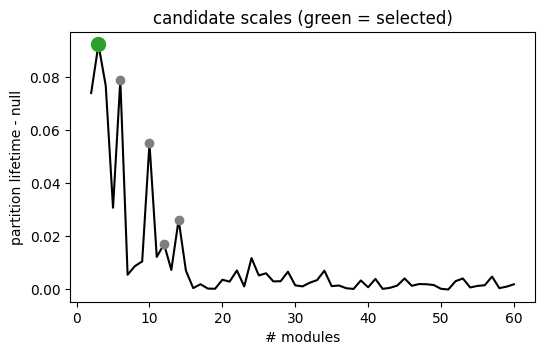

In [10]:
g, modules, _, module_names, module_index, scales = SAM.hierarchical_cluster_features_into_SAM_modules(
    Xw, feat_names, return_scales=True)
plt.close(g.fig)
print(scales[['n_modules', 'n_small_modules', 'coverage', 'lifetime_gap', 'stability', 'consensus_score',
              'selected']].round(3).to_string(index=False))
for m, n in enumerate(module_names[:8]):
    print('module %d (%d features): %s' % (m + 1, len(n), dict(pd.Series(preprocess.sam_feature_groups(n)[1]).value_counts())))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(scales.attrs['k'], scales.attrs['lifetime_gap'], 'k-')
ax.plot(scales.n_modules, scales.lifetime_gap, 'o', color='tab:gray')
ax.plot(scales.n_modules[scales.selected], scales.lifetime_gap[scales.selected], 'o', color='tab:green', ms=10)
ax.set_xlabel('# modules'); ax.set_ylabel('partition lifetime - null'); ax.set_title('candidate scales (green = selected)')
show(fig, '6_module_scales.png')

## 7. UMAP and PaCMAP embeddings
Both are installed with SPOT. The embeddings use the confound-corrected, weighted features; the 10-nearest-neighbour
accuracy of the phenotype measures how well they separate.

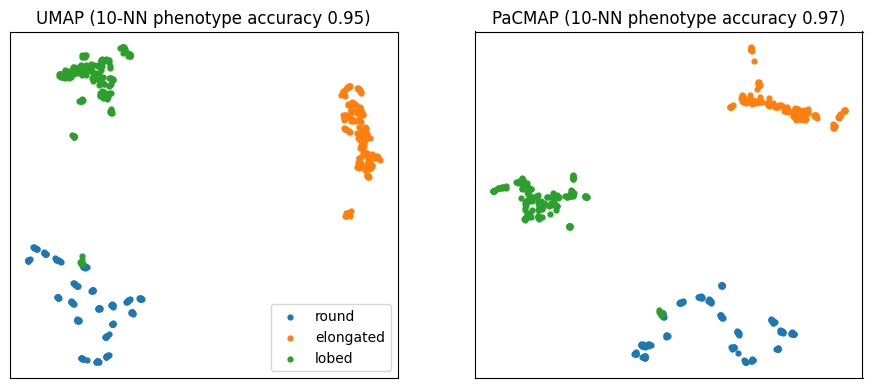

10-NN phenotype accuracy in feature space: unweighted 1.00, weighted 1.00, batch-corrected + weighted 1.00, batch + illumination-corrected + weighted 0.98


In [11]:
import pacmap  # noqa: E402
import umap  # noqa: E402
from sklearn.neighbors import KNeighborsClassifier  # noqa: E402

Xcw = preprocess.weight_sam_features(Xc, names_c)
kinds = meta['kind'].to_numpy()
colors = {'round': 'tab:blue', 'elongated': 'tab:orange', 'lobed': 'tab:green'}


def knn_accuracy(Z):
    return cross_val_score(KNeighborsClassifier(10), Z, kinds, groups=meta['cell'], cv=GroupKFold(4)).mean()


embeddings = {'UMAP': umap.UMAP(n_neighbors=15, random_state=0).fit_transform(Xcw),
              'PaCMAP': pacmap.PaCMAP(n_components=2, random_state=0).fit_transform(Xcw)}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, Z) in zip(axes, embeddings.items()):
    for kind, col in colors.items():
        sel = kinds == kind
        ax.scatter(Z[sel, 0], Z[sel, 1], s=12, c=col, label=kind)
    ax.set_title('%s (10-NN phenotype accuracy %.2f)' % (name, knn_accuracy(Z))); ax.set_xticks([]); ax.set_yticks([])
axes[0].legend()
show(fig, '7_embeddings.png')
print('10-NN phenotype accuracy in feature space: unweighted %.2f, weighted %.2f, batch-corrected + weighted %.2f, '
      'batch + illumination-corrected + weighted %.2f'
      % (knn_accuracy(X), knn_accuracy(Xw), knn_accuracy(preprocess.weight_sam_features(Xb, names_b)), knn_accuracy(Xcw)))

## 8. Pretrained detection and segmentation networks (PyTorch, from Zenodo)
The YOLOv3 organoid detector and the attention U-Net segmentation model are archived on Zenodo
([doi:10.5281/zenodo.23438299](https://doi.org/10.5281/zenodo.23438299)). `get_pretrained_weights` downloads them on
first use, checks their sha256, caches them (`~/.cache/SPOT/models` or `$SPOT_MODELS_DIR`) and converts them to
PyTorch; the PyTorch loaders use them when no weights file is given. Set `DOWNLOAD_WEIGHTS = True` to run this
(~250 MB). TensorFlow is only needed for the original Keras functions (`pip install SAM-SPOT[keras-legacy]`).

In [12]:
from SPOT.Detection.pretrained import PRETRAINED_MODELS, get_pretrained_weights  # noqa: E402

for name, info in PRETRAINED_MODELS.items():
    print('%-32s %s' % (name, info['url']))
if DOWNLOAD_WEIGHTS:
    from SPOT.Detection.detection import load_torch_segmentation_model
    detector_pt = get_pretrained_weights('yolov3_organoid_detector')
    segmenter = load_torch_segmentation_model()  # downloads + converts the attention U-Net
    print('detector weights:', detector_pt)

yolov3_organoid_detector         https://zenodo.org/records/23438299/files/keras_YOLOv3_organoid_detector2.h5?download=1
attn_unet_organoid_segmentation  https://zenodo.org/records/23438299/files/organoid-bbox_attn_seg-unet-master-v2_64x64-8feats_v2.h5?download=1
